# GRS products in an S3 bucket with a STAC catalogue

This notebook finds GRS L2A and GRSl2bgen L2B products from a static STAC catalogue stored in an S3 bucket,
then reads them directly from the bucket, without downloading them: only the chunks needed are transferred.

The bucket is served on the local machine by `rclone serve s3`, in place: the products stay in their
folders. Start it in a terminal, and leave it running while you use this notebook:

```bash
bash s3_bucket.sh
```

The script links the folders of products into the bucket, generates a key, and writes it with the address
of the server in the AWS profile `grstbx-local`. It only needs to be set once per machine, the code below
then contains no key and no address. The same code works on a real bucket, see the last section.

In [1]:
import json
import os
import time
from concurrent.futures import ThreadPoolExecutor

import cmocean  # registers the cmo.* colormaps
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs

from grstbx.app import open_products, search_items
from grstbx.driver import open_zarr_image, zarr_levels

# credentials and endpoint of the bucket (read by s3fs, also in the dask workers)
os.environ.setdefault('AWS_PROFILE', 'grstbx-local')

bucket = 'grstbx-s3'
catalog = f's3://{bucket}/stac/catalog.json'

## Build the catalogue

The catalogue describes the products with their URLs in the bucket. It is written once, and again when
products are added (a few minutes for a thousand products). `grstbx.stac.build_catalog` gives the number of
Items of each collection, and the products left out because they are incomplete. The L2B Items
written by GRSl2bgen are reused, the others come from the attributes of the products. Set `build` to `True`
to run it.

In [2]:
build = False

if build:
    from grstbx import stac

    data = '/data/satellite/Sentinel-2'
    items, skipped = stac.build_catalog({f'{data}/L2A_zarr': f's3://{bucket}/sentinel-2/l2a',
                                         f'{data}/L2B_zarr': f's3://{bucket}/sentinel-2/l2b'},
                                        f'/data/satellite/s3/{bucket}/stac')
    print(items, f'{len(skipped)} incomplete products left out')

## Explore the bucket

The bucket is an object store, explored here with `s3fs`.

In [3]:
fs = s3fs.S3FileSystem()
fs.ls(bucket)

['grstbx-s3/sentinel-2', 'grstbx-s3/stac']

In [4]:
with fsspec.open(catalog) as f:
    root = json.load(f)

collections = []
for link in (link for link in root['links'] if link['rel'] == 'child'):
    with fsspec.open(f's3://{bucket}/stac/' + link['href'][2:]) as f:
        collection = json.load(f)
    interval = collection['extent']['temporal']['interval'][0]
    collections.append({'id': collection['id'], 'title': collection['title'], 'start': interval[0][:10],
                        'end': interval[1][:10], 'tiles': ', '.join(collection['summaries']['grid:code'])})
pd.DataFrame(collections).set_index('id')

,title,start,end,tiles
id,,,,
grs-l2a,GRS L2A,2021-02-11,2025-08-31,"MGRS-31TEJ, MGRS-31TFJ, MGRS-32TQR"
grs-l2b,GRSl2bgen L2B,2022-01-27,2026-04-30,"MGRS-31TFJ, MGRS-31TGJ"


## Search

`grstbx.app.search_items` selects the products by area, period, cloud cover, tile, GRS version and
collection. It reads the Items of the catalogue, not the products: the search takes a moment, whatever
the size of the products. The results have the data asset of each Item in the column `path`.

Here, the L2B products of the Étang de Berre in 2023, on images with less than 20 % of clouds.

In [5]:
berre = (5.03, 43.40, 5.24, 43.56)    # lon_min, lat_min, lon_max, lat_max
period = {'start': '2023-01-01', 'end': '2023-12-31'}

t0 = time.time()
all_images = search_items(catalog, collections='grs-l2b', bbox=berre, **period)
found = all_images[all_images.cloud_cover <= 20].reset_index(drop=True)
print(f'{len(found)} of {len(all_images)} products in {time.time() - t0:.1f} s')
found[['time', 'satellite', 'tile', 'version', 'cloud_cover']].head()

71 of 98 products in 0.2 s


,time,satellite,tile,version,cloud_cover
0,2023-01-04 10:33:29.024,S2B,31TFJ,3.1.0,2.047375
1,2023-01-09 10:34:21.024,S2A,31TFJ,3.1.0,7.108288
2,2023-01-19 10:33:41.024,S2A,31TFJ,3.1.0,4.117612
3,2023-01-29 10:33:01.024,S2A,31TFJ,3.1.0,0.000000
4,2023-02-01 10:42:51.024,S2A,31TFJ,3.1.0,3.502275


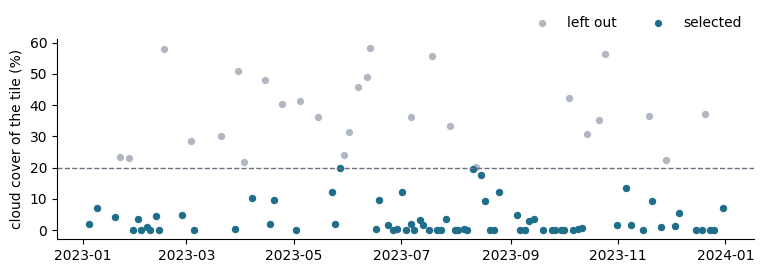

In [6]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.scatter(all_images.time, all_images.cloud_cover, s=18, color='#b0b7c3', label='left out')
ax.scatter(found.time, found.cloud_cover, s=18, color='#1f6f8b', label='selected')
ax.axhline(20, color='#6b7280', lw=1, ls='--')
ax.set_ylabel('cloud cover of the tile (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper right', bbox_to_anchor=(1, 1.18))
plt.show()

## Open a product from the bucket

The clearest image of the selection, opened from its data asset. Opening reads the metadata only.

In [7]:
image = found.loc[found.cloud_cover.idxmin()]
print(image['name'], f'{image.cloud_cover:.1f} % of clouds')

t0 = time.time()
l2b = open_zarr_image(image.path)
print(f'opened in {time.time() - t0:.1f} s, levels of the pyramid: {zarr_levels(image.path)}')
print(f'{len(l2b.data_vars)} variables, {l2b.nbytes / 1e9:.1f} GB uncompressed')

S2A_MSIL2B_20230129T103301_N0509_R108_T31TFJ_20230129T140905_V3.1.0 0.0 % of clouds


opened in 1.0 s, levels of the pyramid: ['0', '1', '2', '3', '4']
29 variables, 7.5 GB uncompressed


The next cell reads one parameter on the lake, at full resolution: only the chunks over the lake are
requested, not the 110 km of the tile.

796176 pixels read in 0.6 s


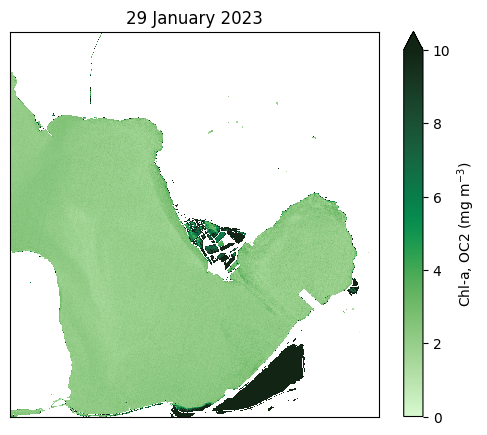

In [8]:
def lake(ds):
    """Part of a product over the area, with the pixels of valid water."""
    ds = ds.rio.clip_box(*berre, crs='EPSG:4326')
    return ds.where(ds['mask'] == 0)


t0 = time.time()
chla = lake(l2b[['Chla_OC2nasa', 'mask']])['Chla_OC2nasa'].compute()
print(f'{chla.size} pixels read in {time.time() - t0:.1f} s')

fig, ax = plt.subplots(figsize=(6.5, 5))
chla.plot(ax=ax, cmap='cmo.algae', vmin=0, vmax=10, cbar_kwargs={'label': 'Chl-a, OC2 (mg m$^{-3}$)'})
ax.set_aspect('equal')
ax.set_title(f'{image.time:%d %B %Y}')
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

## From the L2B product to its L2A product

Each L2B Item has a `derived_from` link to the Item of its L2A product, when it is in the catalogue. The
quick look uses a coarse level of the pyramid (`level=2`, 80 m): the whole tile is read in a few seconds.

s3://grstbx-s3/sentinel-2/l2a/31TFJ/2023/01/29/S2A_MSIL2AGRS_20230129T103301_N0509_R108_T31TFJ_20230129T140905_V3.1.0/S2A_MSIL2AGRS_20230129T103301_N0509_R108_T31TFJ_20230129T140905_V3.1.0.zarr


read in 1.6 s


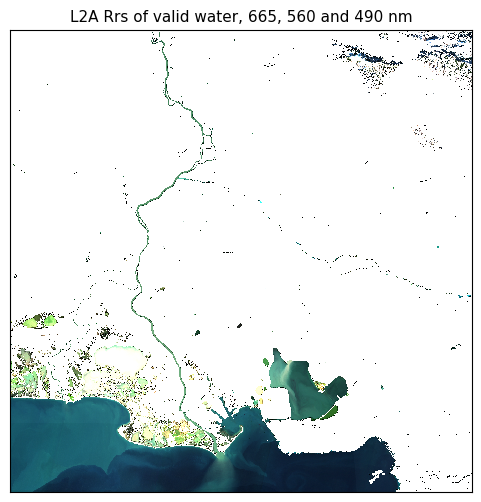

In [9]:
with fsspec.open(image['item']) as f:
    item = json.load(f)
link = next(link for link in item['links'] if link['rel'] == 'derived_from')
l2a_name = os.path.basename(link['href'])[:-len('.json')]

l2a_items = search_items(catalog, collections='grs-l2a', **period)
l2a_path = l2a_items.set_index('name').loc[l2a_name, 'path']
print(l2a_path)

t0 = time.time()
l2a = open_zarr_image(l2a_path, level=2)
rgb = l2a['Rrs'].sel(wl=[665, 560, 490], method='nearest').where(l2a['mask'] == 0).compute()
print(f'read in {time.time() - t0:.1f} s')

fig, ax = plt.subplots(figsize=(6, 6))
(rgb / 0.03).clip(0, 1).fillna(1).plot.imshow(ax=ax, rgb='wl', add_labels=False)
ax.set_aspect('equal')
ax.set_title('L2A Rrs of valid water, 665, 560 and 490 nm', fontsize=11)
ax.set_xticks([])
ax.set_yticks([])
plt.show()

## Time series

The search gives the products of the time series. Each image is opened lazily and only the part over the
lake is read, a few images at a time. The images with too few valid pixels are left out.

In [10]:
def lake_values(row, params=('Chla_OC2nasa', 'SPM_nechad'), min_valid=0.1):
    ds = lake(open_zarr_image(row.path)[[*params, 'mask']]).compute()
    water = ds[params[0]].notnull().mean().item()
    values = {param: float(ds[param].median()) for param in params} if water >= min_valid else {}
    return {'time': row.time, 'valid_water': water, **values}


t0 = time.time()
with ThreadPoolExecutor(6) as pool:
    series = pd.DataFrame(pool.map(lake_values, found.itertuples())).set_index('time')
print(f'{len(series)} images read in {time.time() - t0:.0f} s, '
      f'{series.Chla_OC2nasa.notna().sum()} with at least 10 % of valid pixels')

71 images read in 49 s, 68 with at least 10 % of valid pixels


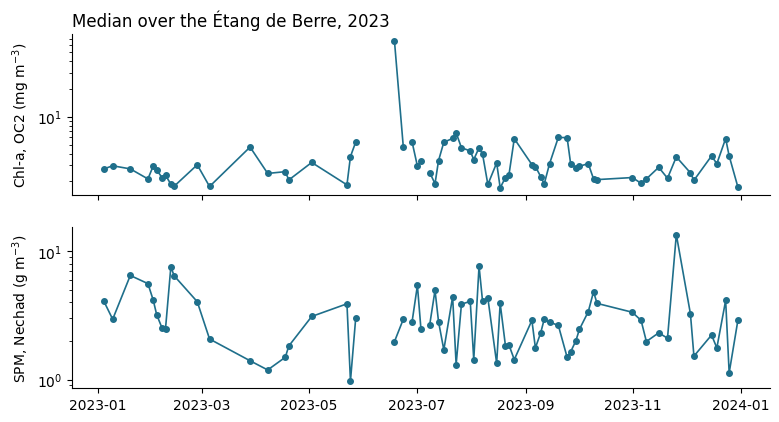

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
labels = {'Chla_OC2nasa': 'Chl-a, OC2 (mg m$^{-3}$)', 'SPM_nechad': 'SPM, Nechad (g m$^{-3}$)'}
for ax, (param, label) in zip(axes, labels.items()):
    ax.plot(series.index, series[param], '-o', lw=1.2, ms=4, color='#1f6f8b')
    ax.set_ylabel(label)
    ax.set_yscale('log')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title('Median over the Étang de Berre, 2023', loc='left')
plt.show()

An isolated peak is not necessarily a bloom: look at the part of the area with valid water
(`valid_water`) and at the image itself before interpreting it.

In [12]:
series.sort_values('Chla_OC2nasa', ascending=False).head(3).round(2)

,valid_water,Chla_OC2nasa,SPM_nechad
time,,,
2023-06-18 10:26:01.024,0.32,65.93,1.98
2023-07-23 10:26:09.024,0.45,6.70,1.31
2023-09-19 10:37:21.024,0.46,5.99,2.65


## Viewers and dashboard

The URLs of the search are accepted by `grstbx.app.open_products`, as local paths, so the viewers
of grstbx open the time series lazily from the bucket.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
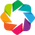

L2B 71 products, 22 parameters


In [13]:
data, kind, params, title = open_products(list(found.path))
print(kind, len(found), 'products,', len(params), 'parameters')

## Moving to a real bucket

The notebook does not depend on the local server. For a bucket on AWS or on the object storage of a data
centre:

1. copy the products with their folders, and set the URLs of the bucket in `build_catalog` before
   publishing the catalogue, e.g. `rclone copy /data/satellite/Sentinel-2/L2A_zarr remote:my-bucket/sentinel-2/l2a`;
2. replace the profile `grstbx-local` by a profile with the credentials of this bucket (and its
   `endpoint_url`, except on AWS), and `bucket` by its name.

Choose the name of a local bucket with care: without its profile, an `s3://` URL goes to AWS, where
names are shared by everyone.